In [65]:
%load_ext autoreload
%autoreload 2
import os
from pathlib import Path
import numpy as np
import polars as pl
import pandas as pd
import scipy.sparse
import matplotlib.pyplot as plt
import seaborn as sns
from utils import pipeline_v2, funcs
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import accuracy_score
from sklearn.base import clone
from sklearn.metrics import (f1_score, classification_report,ConfusionMatrixDisplay,confusion_matrix, roc_curve, auc)
from sklearn.preprocessing import label_binarize
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from gensim.models.doc2vec import Doc2Vec, TaggedDocument
from sklearn.naive_bayes import GaussianNB, MultinomialNB, BernoulliNB
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, HistGradientBoostingClassifier, StackingClassifier

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [55]:
train_full_base=pl.read_parquet(r'data\data-w2v\cleaned_train_df_tokenized.parquet')
train_full_base = train_full_base.filter(pl.col("cleaned_lyrics").list.len() > 10)

X=train_full_base['cleaned_lyrics'].to_list()
y=train_full_base['tag']

X_train_base,  X_val_base, y_train_base, y_val_base = train_test_split(X,y, stratify=y, random_state=69, test_size=0.3)

In [56]:
vectorized_train = {}
vectorized_val = {}
max_n_gram = 3

X_train_str = [" ".join(doc) for doc in X_train_base]
X_val_str = [" ".join(doc) for doc in X_val_base]

tfidf = TfidfVectorizer(ngram_range=(1, max_n_gram))
vectorized_train['TFIDF'] = tfidf.fit_transform(X_train_str)
vectorized_val['TFIDF'] = tfidf.transform(X_val_str)
print("TF-IDF complete.")

TF-IDF complete.


In [57]:
count = CountVectorizer(ngram_range=(1, max_n_gram))
vectorized_train['Count'] = count.fit_transform(X_train_str)
vectorized_val['Count'] = count.transform(X_val_str)
print("Count Vectorizer complete.")

Count Vectorizer complete.


In [58]:
tagged_data = [TaggedDocument(words=doc, tags=[str(i)]) for i, doc in enumerate(X_train_base)]

d2v = Doc2Vec(vector_size=100, min_count=2, epochs=20, workers=6)
d2v.build_vocab(tagged_data)
d2v.train(tagged_data, total_examples=d2v.corpus_count, epochs=d2v.epochs)

vectorized_train['Doc2Vec'] = np.array([d2v.infer_vector(doc if isinstance(doc, list) else str(doc).split()) for doc in X_train_base])
vectorized_val['Doc2Vec'] = np.array([d2v.infer_vector(doc if isinstance(doc, list) else str(doc).split()) for doc in X_val_base])
print("Doc2Vec complete.")

Doc2Vec complete.


In [62]:
model_configs = [
        ('Doc2Vec', 'GaussianNB', GaussianNB()),
        ('TFIDF', 'MultinomialNB', MultinomialNB()),
        ('Count', 'MultinomialNB', MultinomialNB()),
        ('TFIDF', 'BernoulliNB', BernoulliNB()),
        ('Count', 'BernoulliNB', BernoulliNB())
    ]

In [63]:
def train_and_compare_selected(vectorized_train, vectorized_val, y_train, y_val, model_configs):

    # Create 2x3 grids (6 subplots total, 5 used, 1 hidden)
    fig_cm, axes_cm = plt.subplots(2, 3, figsize=(18, 12))
    fig_cm.suptitle("Confusion Matrices (Validation)", fontsize=16)
    
    fig_f1, axes_f1 = plt.subplots(2, 3, figsize=(18, 12))
    fig_f1.suptitle("Macro F1 Scores (Train vs Validation)", fontsize=16)

    axes_cm_flat = axes_cm.flatten()
    axes_f1_flat = axes_f1.flatten()
    trained_models = {}

    for i, (v_name, m_name, clf) in enumerate(model_configs):
        print(f"Training {v_name} + {m_name}...")
        
        X_t = vectorized_train[v_name]
        X_v = vectorized_val[v_name]
        
        # Train
        clf.fit(X_t, y_train)
        
        # Predict
        y_train_pred = clf.predict(X_t)
        y_val_pred = clf.predict(X_v)
        
        # Metrics
        train_f1 = f1_score(y_train, y_train_pred, average='macro')
        val_f1 = f1_score(y_val, y_val_pred, average='macro')
        
        # Confusion Matrix
        cm = confusion_matrix(y_val, y_val_pred)
        sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes_cm_flat[i])
        axes_cm_flat[i].set_title(f"{v_name} + {m_name}")
        axes_cm_flat[i].set_xlabel("Predicted")
        axes_cm_flat[i].set_ylabel("Actual")
        
        # F1 Bar Plot
        axes_f1_flat[i].bar(['Train', 'Validation'], [train_f1, val_f1], color=['#4C72B0', '#DD8452'])
        axes_f1_flat[i].set_ylim(0, 1.05)
        axes_f1_flat[i].set_title(f"{v_name} + {m_name}\nTrain: {train_f1:.3f} | Val: {val_f1:.3f}")
        for index, value in enumerate([train_f1, val_f1]):
            axes_f1_flat[i].text(index, value + 0.02, f"{value:.3f}", ha='center')

        trained_models[f"{v_name}_{m_name}"] = clf

    # Hide the 6th unused subplot
    axes_cm_flat[5].set_visible(False)
    axes_f1_flat[5].set_visible(False)

    fig_cm.tight_layout(rect=[0, 0.03, 1, 0.95])
    fig_f1.tight_layout(rect=[0, 0.03, 1, 0.95])
    plt.show()

    return trained_models

Training Doc2Vec + GaussianNB...
Training TFIDF + MultinomialNB...
Training Count + MultinomialNB...
Training TFIDF + BernoulliNB...
Training Count + BernoulliNB...


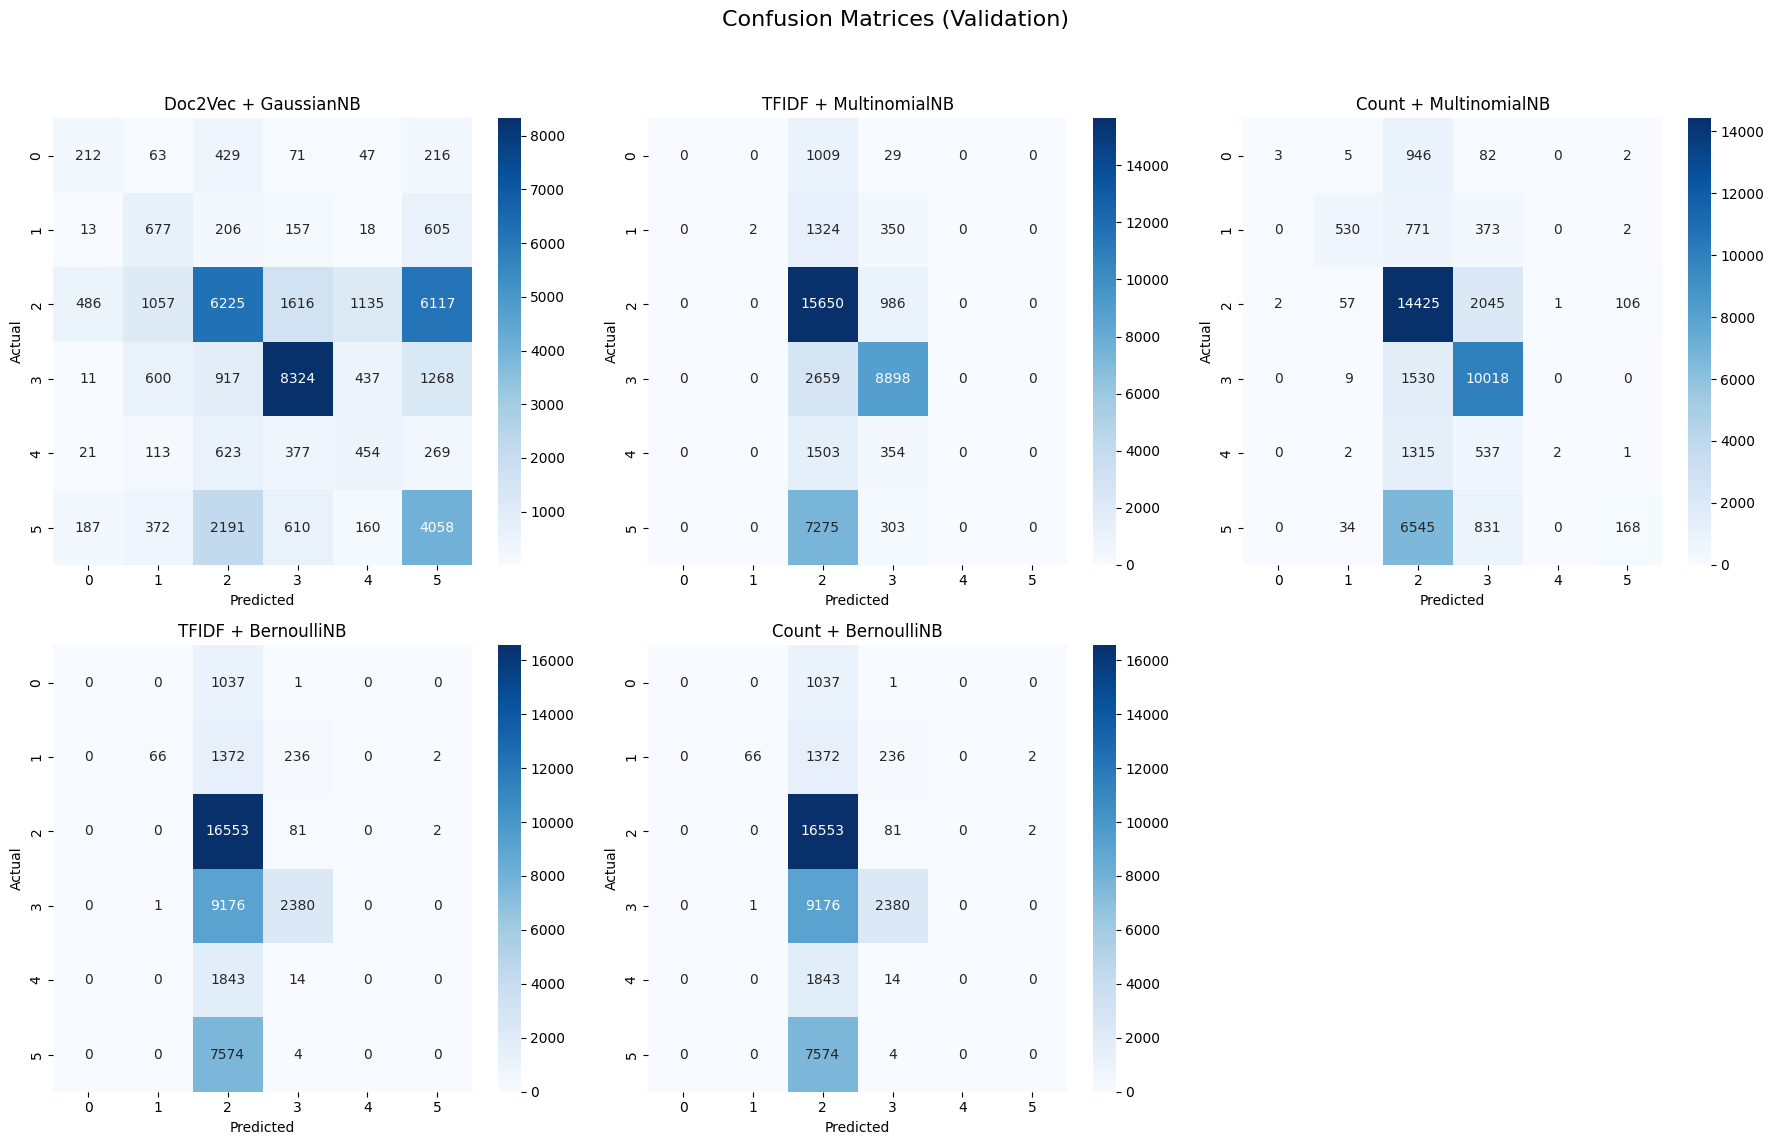

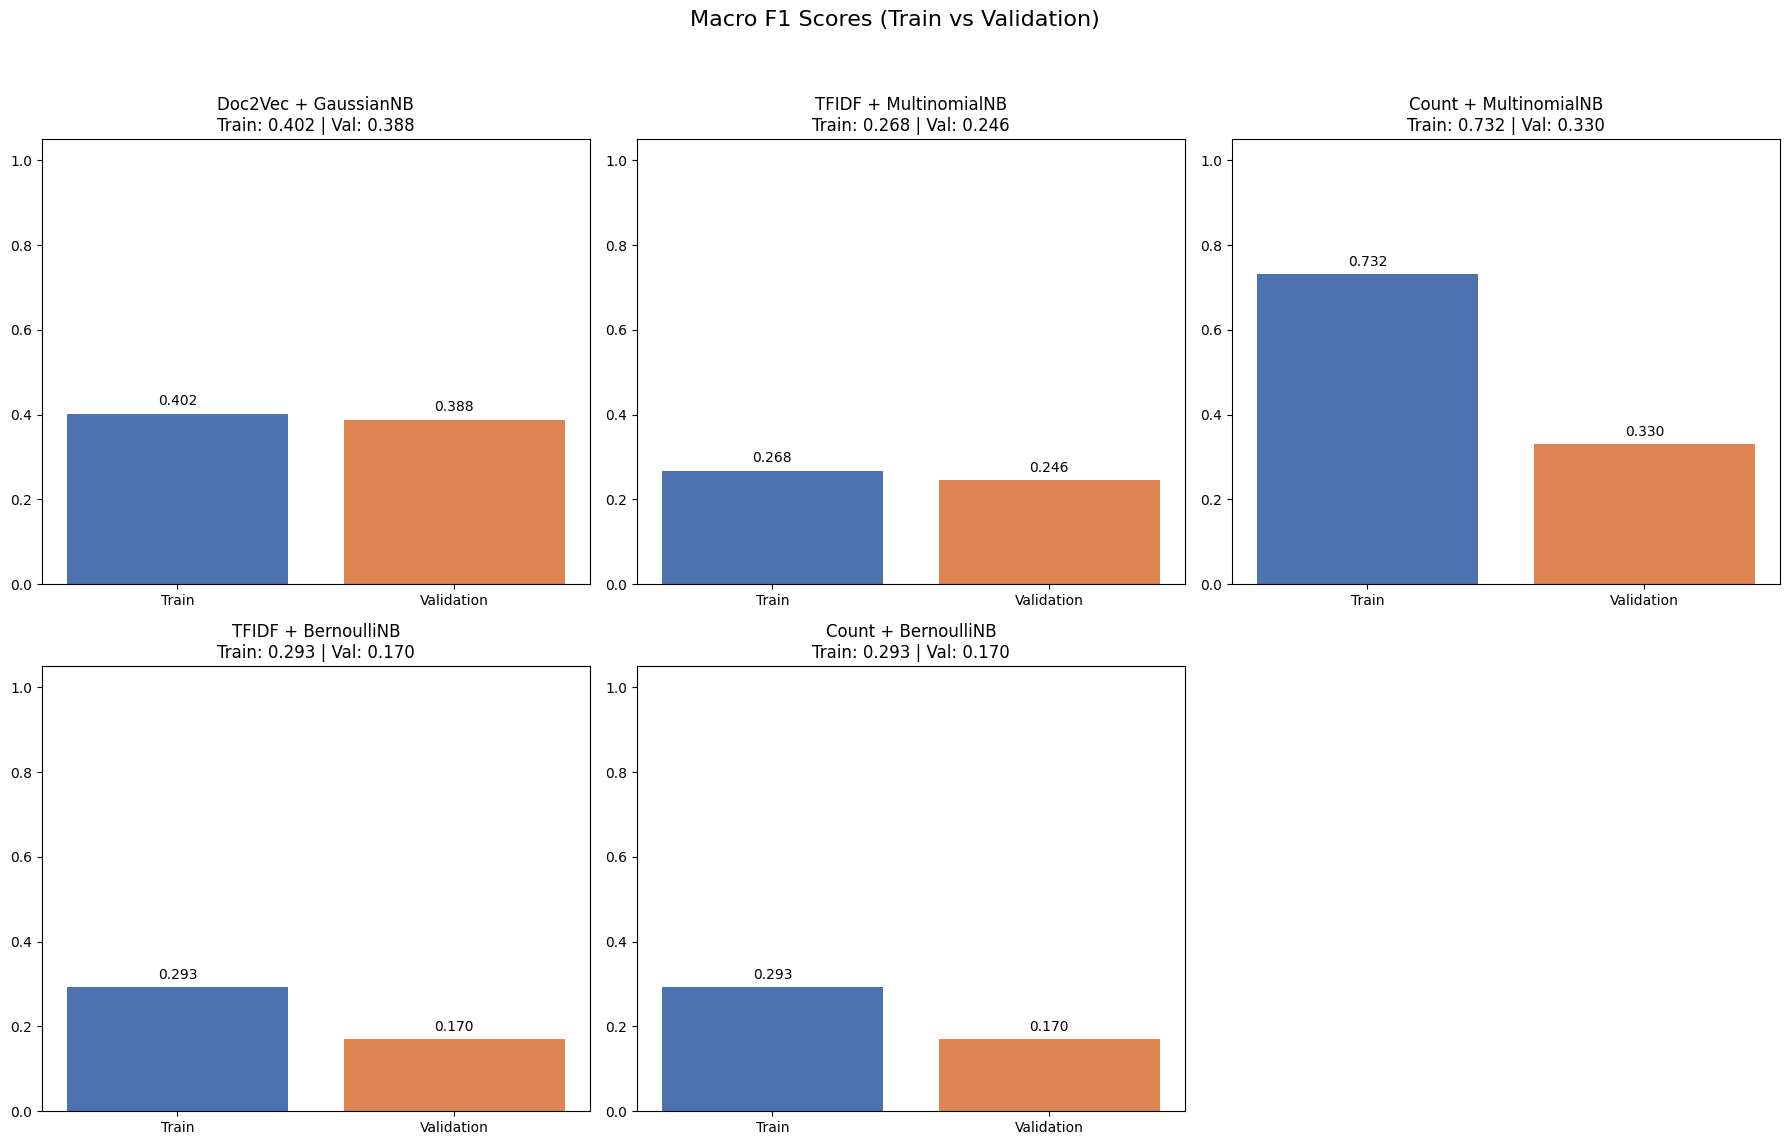

In [64]:
trained_models = train_and_compare_selected(vectorized_train, vectorized_val, y_train_base, y_val_base, model_configs)

In [72]:
train_glove=pl.read_parquet(r'data\data-Classic\train_glove_tfidf.parquet')
val_glove=pl.read_parquet(r'data\data-Classic\val_glove_tfidf.parquet')

In [73]:
splits = pl.read_parquet("data/splits.parquet")
val_ids = splits.filter(pl.col("split") == "val")["id"]

In [74]:
X_train_gv=train_glove.drop(['genre'])
y_train_gv=train_glove['genre']
X_val_gv=val_glove.drop(['genre'])
y_val_gv=val_glove['genre']

In [75]:
rfc = RandomForestClassifier(
    n_estimators=300,
    min_samples_leaf=5,
    class_weight="balanced_subsample",
    n_jobs=-1,
    random_state=0,
)
rfc.fit(X_train_gv, y_train_gv)

,n_estimators,300
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,5
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [76]:
rfc_ub = RandomForestClassifier(
    n_estimators=300,
    min_samples_leaf=5,
    n_jobs=-1,
    random_state=0,
)
rfc.fit(X_train_gv, y_train_gv)

,n_estimators,300
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,5
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [77]:
xtc = ExtraTreesClassifier(
    n_estimators=300,
    min_samples_leaf=50,
    class_weight="balanced_subsample",
    n_jobs=-1,
    random_state=0
)
xtc.fit(X_train_gv,y_train_gv)

,n_estimators,300
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,50
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,False
,oob_score,False


In [78]:
hgb = HistGradientBoostingClassifier(
    max_iter=300, min_samples_leaf=50, early_stopping=True,
    n_iter_no_change=10, validation_fraction=0.3, random_state=0,
    l2_regularization=0.1, class_weight="balanced", learning_rate=0.05
)
hgb.fit(X_train_gv,y_train_gv)

,loss,'log_loss'
,learning_rate,0.05
,max_iter,300
,max_leaf_nodes,31
,max_depth,None
,min_samples_leaf,50
,l2_regularization,0.1
,max_features,1.0
,max_bins,255
,categorical_features,'from_dtype'
,monotonic_cst,None


In [79]:
hgb_ub = HistGradientBoostingClassifier(
    max_iter=300, min_samples_leaf=50, early_stopping=True,
    n_iter_no_change=10, validation_fraction=0.3, random_state=0,
    l2_regularization=0.1, learning_rate=0.05
)
hgb.fit(X_train_gv, y_train_gv)

,loss,'log_loss'
,learning_rate,0.05
,max_iter,300
,max_leaf_nodes,31
,max_depth,None
,min_samples_leaf,50
,l2_regularization,0.1
,max_features,1.0
,max_bins,255
,categorical_features,'from_dtype'
,monotonic_cst,None


In [83]:
print('RandomForest')
print('---------------------------------------------------------------------------------------------')
print(f'training: {rfc.score(X_train_gv, y_train_gv)}, testing: {rfc.score(X_val_gv, y_val_gv)}')
print('======================================================')
print('HistGradientBoosting')
print('---------------------------------------------------------------------------------------------')
print(f'training: {hgb.score(X_train_gv, y_train_gv)}, testing: {hgb.score(X_val_gv, y_val_gv)}')
print('======================================================')
print('ExtraTrees')
print('---------------------------------------------------------------------------------------------')
print(f'training: {xtc.score(X_train_gv, y_train_gv)}, testing: {xtc.score(X_val_gv, y_val_gv)}')


RandomForest
---------------------------------------------------------------------------------------------
training: 0.9087851539701853, testing: 0.6305121965695294
HistGradientBoosting
---------------------------------------------------------------------------------------------
training: 0.5874212343334224, testing: 0.5262923615644846
ExtraTrees
---------------------------------------------------------------------------------------------
training: 0.4674600112769683, testing: 0.4361089678912695


In [81]:
estimators = [('RandomForest', rfc), ('RandomForestUnbalanced', rfc_ub), ('HistGradientBoosting', hgb), ('HistGradientBoostingUnbalanced', hgb_ub)]
stack = StackingClassifier(estimators, final_estimator=MultinomialNB())
stack.fit(X_train_gv, y_train_gv)

,estimators,"[('RandomForest', ...), ('RandomForestUnbalanced', ...), ...]"
,final_estimator,MultinomialNB()
,cv,None
,stack_method,'auto'
,n_jobs,None
,passthrough,False
,verbose,0
,n_estimators,300
,criterion,'gini'
,max_depth,None
,min_samples_split,2


In [ ]:
vectorized_train.write_

RandomForest
train accuracy: 0.909
val accuracy:   0.631  (always guessing the biggest genre: 0.412)
macro F1:       0.456
weighted F1:    0.615
              precision    recall  f1-score   support

     country       0.39      0.06      0.10       866
        misc       0.51      0.55      0.53      1405
         pop       0.61      0.69      0.65     13900
         rap       0.80      0.85      0.82      9646
          rb       0.29      0.20      0.24      1550
        rock       0.45      0.35      0.40      6331

    accuracy                           0.63     33698
   macro avg       0.51      0.45      0.46     33698
weighted avg       0.61      0.63      0.61     33698



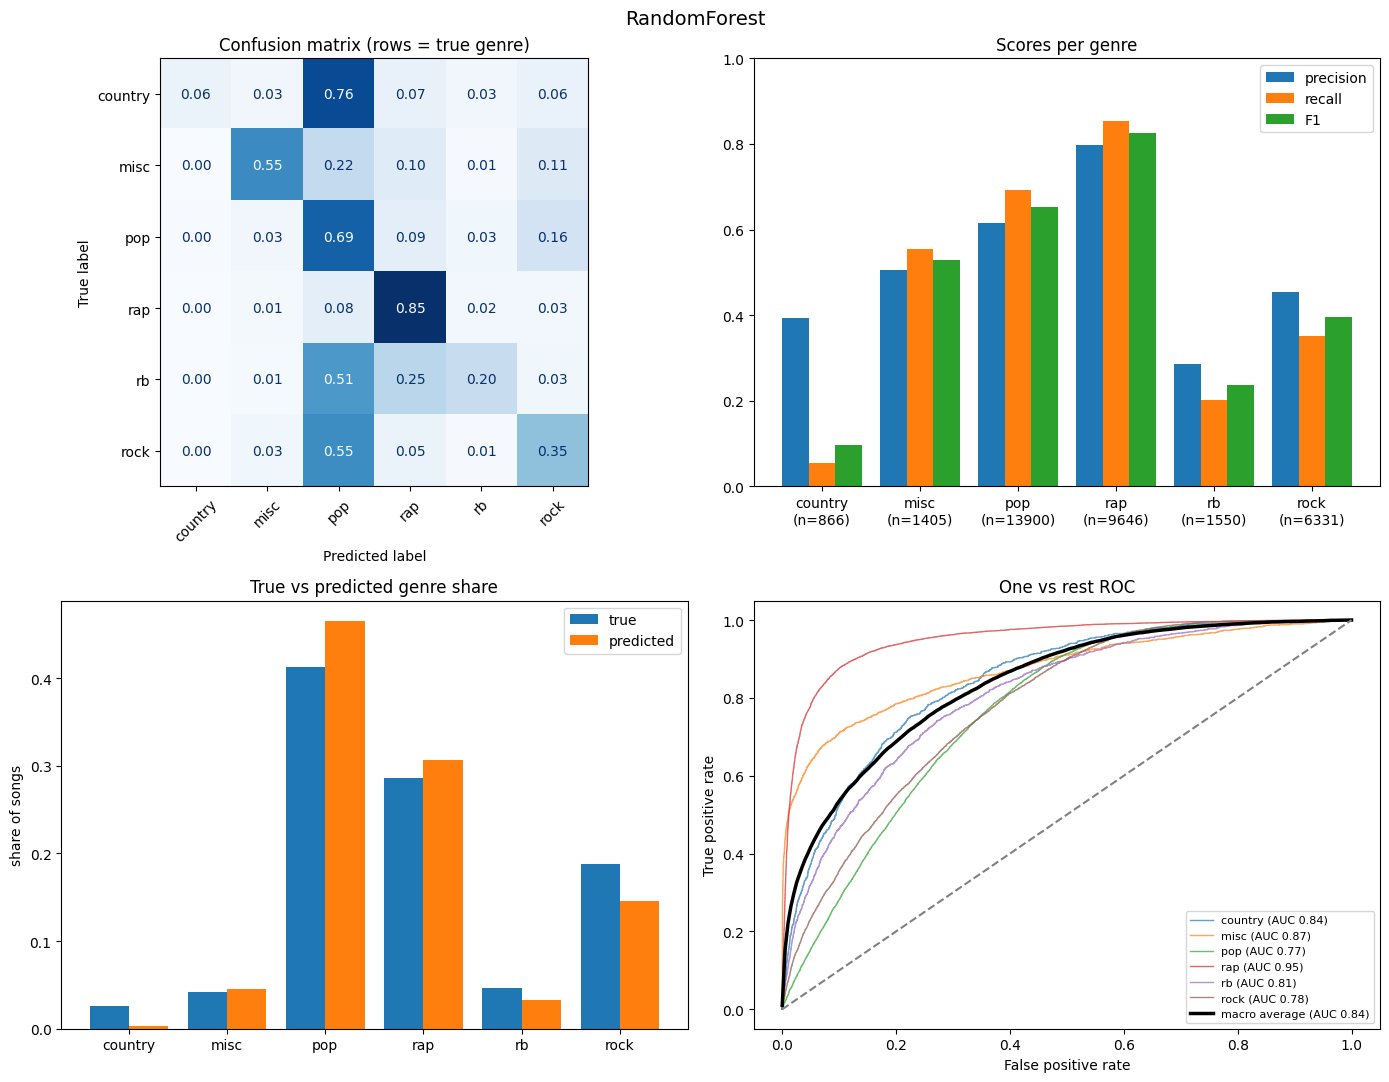

HistGradientBoosting
train accuracy: 0.909
val accuracy:   0.526  (always guessing the biggest genre: 0.412)
macro F1:       0.450
weighted F1:    0.542
              precision    recall  f1-score   support

     country       0.14      0.52      0.22       866
        misc       0.40      0.63      0.49      1405
         pop       0.65      0.32      0.43     13900
         rap       0.86      0.82      0.84      9646
          rb       0.18      0.51      0.27      1550
        rock       0.42      0.51      0.46      6331

    accuracy                           0.53     33698
   macro avg       0.44      0.55      0.45     33698
weighted avg       0.62      0.53      0.54     33698



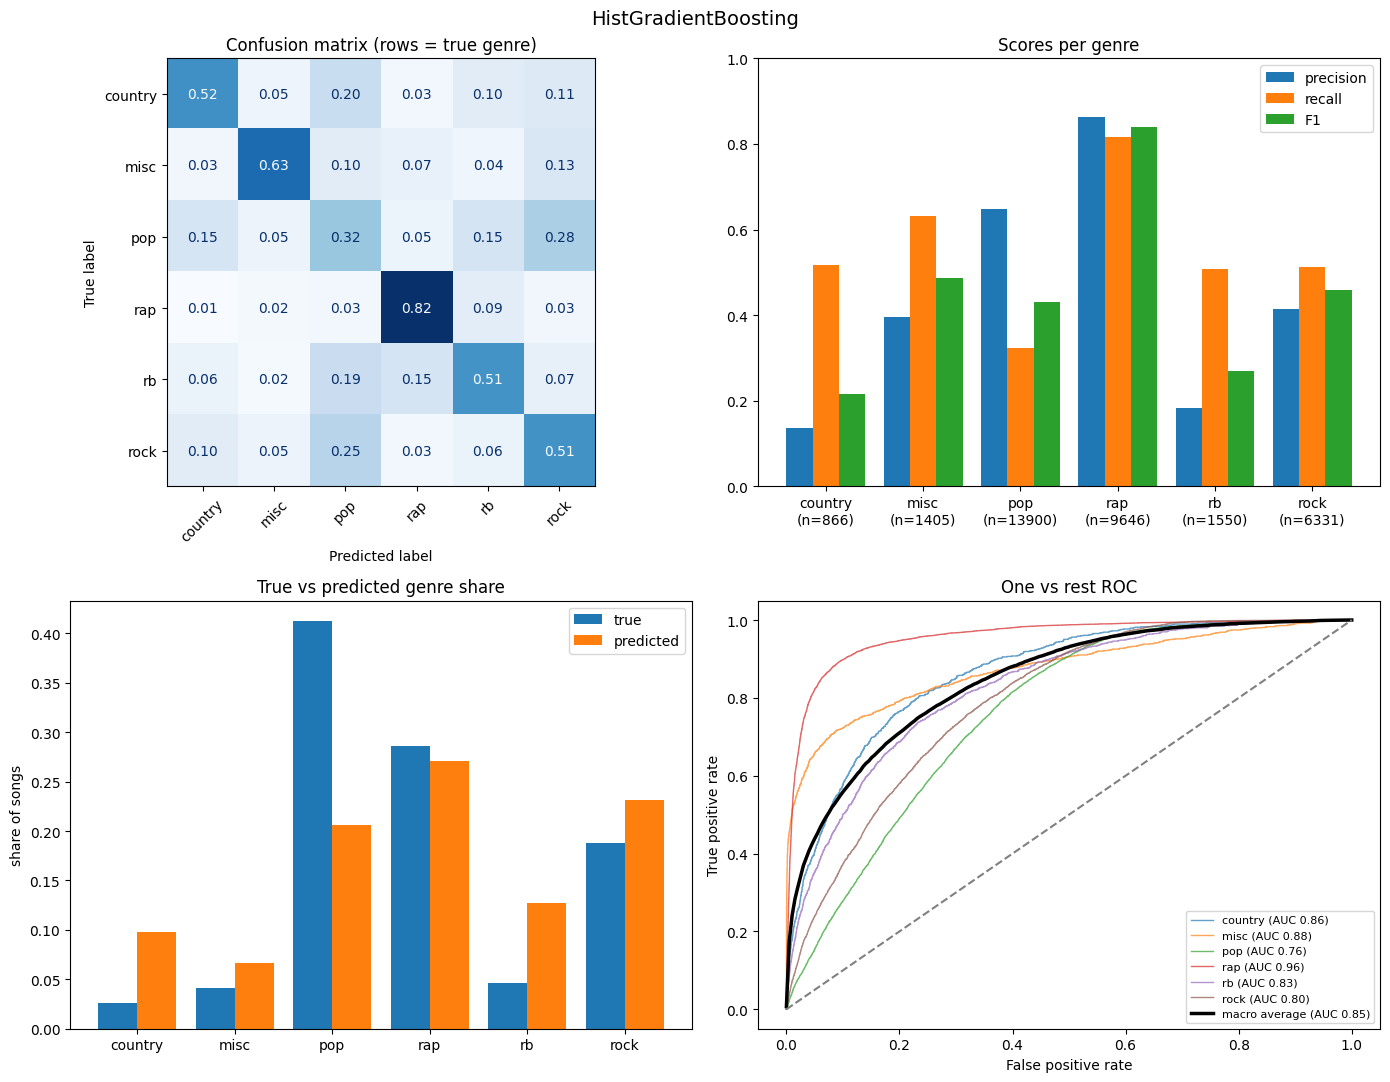

ExtraTrees
train accuracy: 0.909
val accuracy:   0.436  (always guessing the biggest genre: 0.412)
macro F1:       0.369
weighted F1:    0.436
              precision    recall  f1-score   support

     country       0.10      0.51      0.17       866
        misc       0.25      0.67      0.37      1405
         pop       0.65      0.15      0.24     13900
         rap       0.81      0.80      0.81      9646
          rb       0.14      0.55      0.22      1550
        rock       0.39      0.42      0.40      6331

    accuracy                           0.44     33698
   macro avg       0.39      0.52      0.37     33698
weighted avg       0.59      0.44      0.44     33698



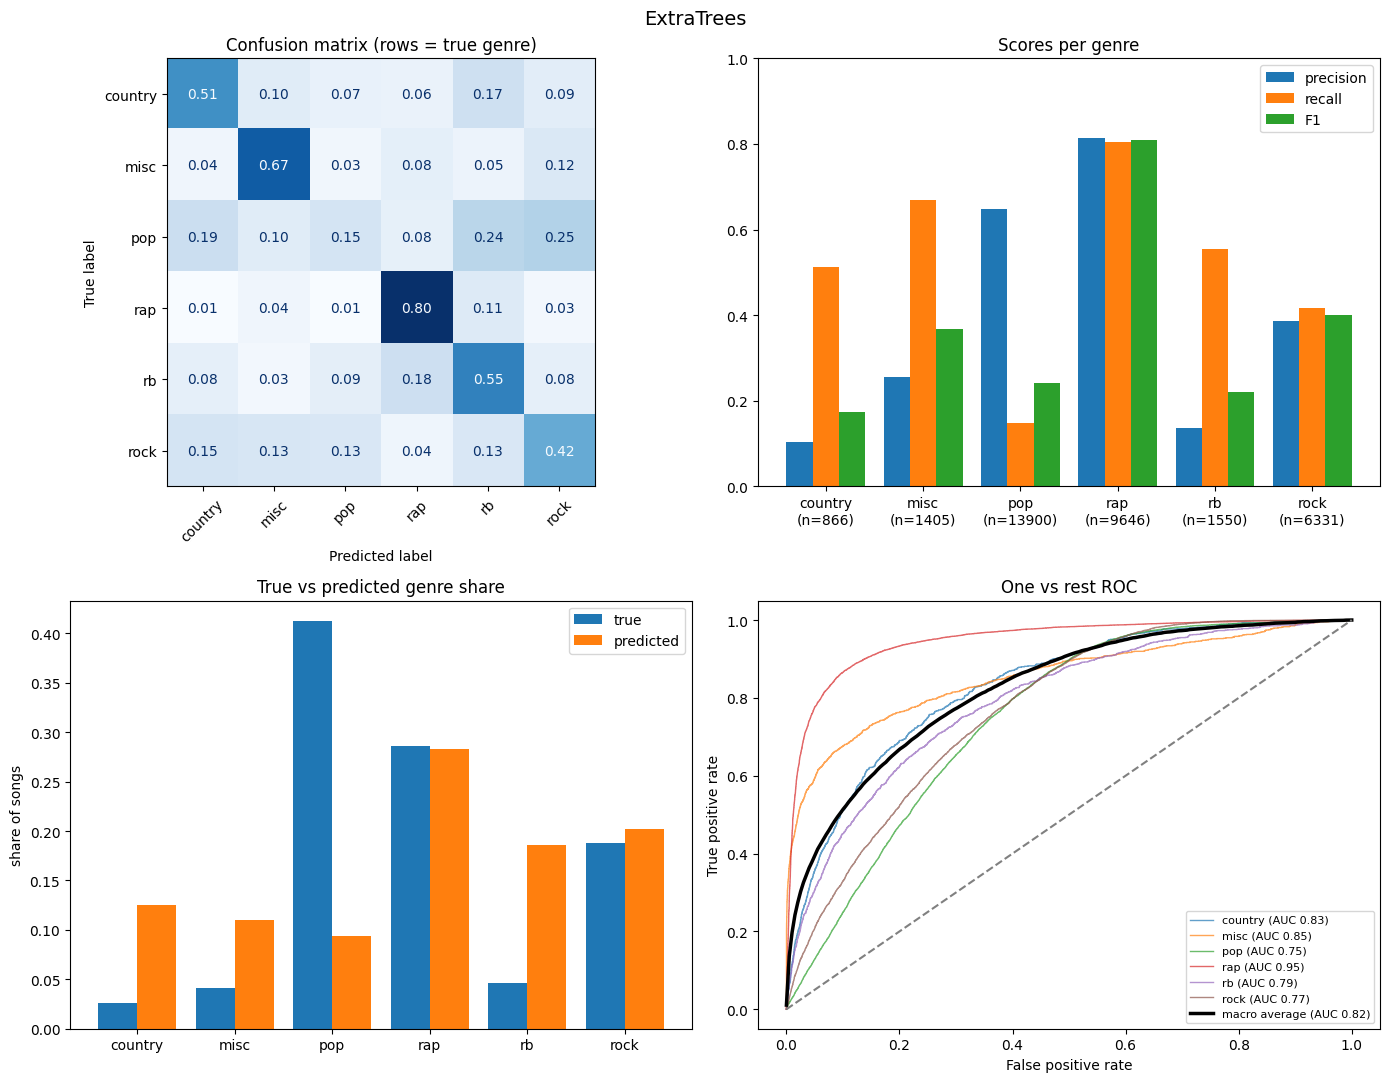

StackingClassifier
train accuracy: 0.909
val accuracy:   0.649  (always guessing the biggest genre: 0.412)
macro F1:       0.360
weighted F1:    0.559
              precision    recall  f1-score   support

     country       0.00      0.00      0.00       866
        misc       0.75      0.49      0.59      1405
         pop       0.56      0.94      0.70     13900
         rap       0.85      0.84      0.85      9646
          rb       0.40      0.01      0.01      1550
        rock       0.84      0.01      0.01      6331

    accuracy                           0.65     33698
   macro avg       0.57      0.38      0.36     33698
weighted avg       0.68      0.65      0.56     33698



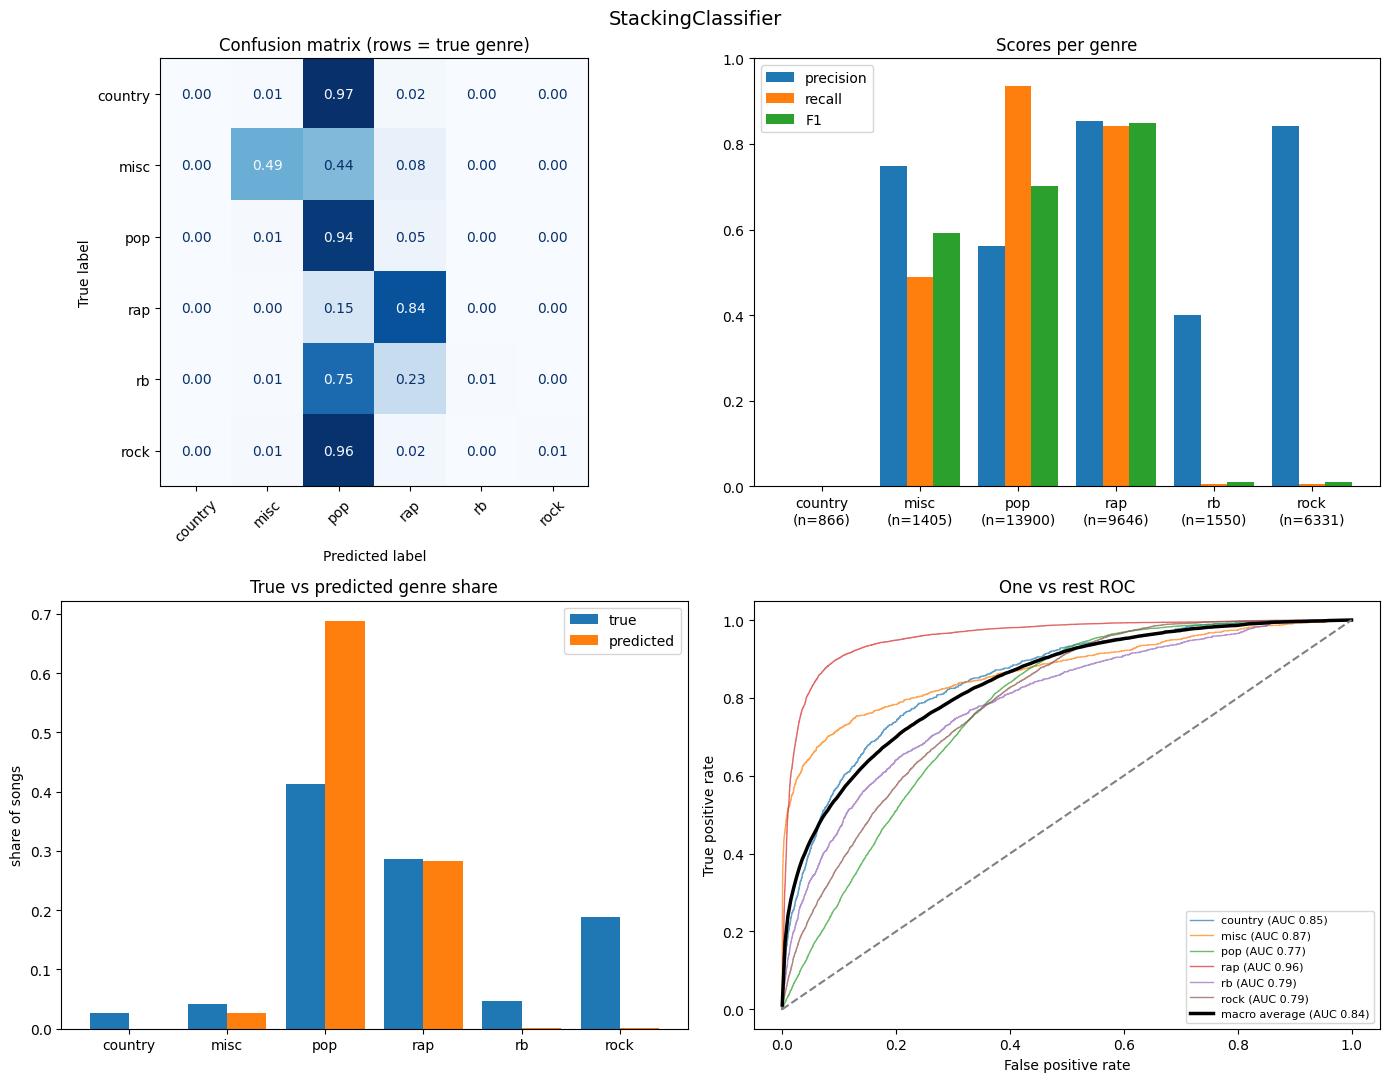

In [ ]:
from utils.funcs import diagnose
models = {'RandomForest': rfc, 'HistGradientBoosting': hgb, 'ExtraTrees': xtc, 'StackingClassifier': stack}
for name, model in models.items():
    print('==============================')
    print(name)
    print('==============================')
    diagnose(y_val_gv, model.predict_proba(X_val_gv), model.classes_,
         name=name, train_accuracy=rfc.score(X_train_gv, y_train_gv))


In [67]:
import time
from sklearn.model_selection import ParameterGrid

grid = ParameterGrid({
    "max_leaf_nodes": [15, 31],
    "min_samples_leaf": [20, 100],
    "l2_regularization": [0.0, 1.0],
    "class_weight": [None, "balanced"],
})

idx = np.random.default_rng(0).choice(len(X_train), size=30000, replace=False)
Xs, ys = np.asarray(X_train)[idx], np.asarray(y_train)[idx]

rows = []
for i, params in enumerate(grid, 1):
    t = time.time()
    m = HistGradientBoostingClassifier(
        max_iter=300, learning_rate=0.1, early_stopping=True, scoring="f1_macro",
        validation_fraction=0.1, n_iter_no_change=15, random_state=0, **params)
    m.fit(Xs, ys)
    pred = m.predict(X_val)
    rows.append({**params, "iters": m.n_iter_, "acc": accuracy_score(y_val, pred),
                 "macro_f1": f1_score(y_val, pred, average="macro"), "secs": time.time() - t})
    print(i, "of", len(grid), rows[-1], flush=True)

results = pd.DataFrame(rows).sort_values("macro_f1", ascending=False)
print(results.to_string(index=False))

1 of 16 {'class_weight': None, 'l2_regularization': 0.0, 'max_leaf_nodes': 15, 'min_samples_leaf': 20, 'iters': 80, 'acc': 0.6553801412546739, 'macro_f1': 0.4236837498383261, 'secs': 36.47916579246521}
2 of 16 {'class_weight': None, 'l2_regularization': 0.0, 'max_leaf_nodes': 15, 'min_samples_leaf': 100, 'iters': 135, 'acc': 0.6558846222327734, 'macro_f1': 0.4340509409523297, 'secs': 58.41244316101074}
3 of 16 {'class_weight': None, 'l2_regularization': 0.0, 'max_leaf_nodes': 31, 'min_samples_leaf': 20, 'iters': 86, 'acc': 0.6529467624191346, 'macro_f1': 0.42518004311201674, 'secs': 62.128023624420166}
4 of 16 {'class_weight': None, 'l2_regularization': 0.0, 'max_leaf_nodes': 31, 'min_samples_leaf': 100, 'iters': 57, 'acc': 0.6571606623538488, 'macro_f1': 0.43300563517847435, 'secs': 42.10882782936096}
5 of 16 {'class_weight': None, 'l2_regularization': 1.0, 'max_leaf_nodes': 15, 'min_samples_leaf': 20, 'iters': 104, 'acc': 0.6576057926286426, 'macro_f1': 0.43045693720420114, 'secs': 4

In [ ]:
test_df = pl.read_parquet('data/data-RF/test_glove_tfidf.parquet')

In [ ]:
df_submission = test_df.select("id").with_columns(
    pl.Series(name="tag", values=rfc.predict(test_df))
)

In [ ]:
df_submission.write_csv('group5_2nd_submit.csv')